# Laboratório: texto como dado

**A pergunta: do que reclamam os clientes da Olist?** A nota diz quanto o cliente ficou
insatisfeito; o comentário diz por quê. Neste laboratório transformamos os comentários em
tokens, contamos, e chegamos às expressões que marcam as avaliações ruins: a primeira resposta.

Escopo de hoje: este laboratório (texto como dado) e o próximo (higiene de corpus). **Na próxima
semana: representações vetoriais de texto (embeddings)**, que agrupam as avaliações pelo sentido.

Roteiro, na ordem dos slides: os dados → token e tipo → do texto ao byte → split e regex →
tokenizadores prontos → estatísticas → stopwords → Zipf → a primeira resposta.

## 0. Preparação

O notebook roda no **Google Colab** ou no seu computador. A primeira célula instala as bibliotecas
que faltam (rode uma vez); a de dados baixa as avaliações da Olist direto do Kaggle com `curl`, sem
conta. Se o download falhar, baixe o zip pelo navegador em
`kaggle.com/datasets/olistbr/brazilian-ecommerce` e extraia `olist_order_reviews_dataset.csv` na
pasta `dados_olist/`.

In [1]:
# Instala o que falta: no Colab, só as bibliotecas de texto; no seu computador, tudo
%pip install -q pandas numpy matplotlib regex tiktoken nltk spacy

import importlib, subprocess, sys
import nltk
nltk.download("punkt_tab", quiet=True)   # o tokenizador de sentenças do NLTK
nltk.download("stopwords", quiet=True)   # a lista de stopwords em português
try:
    import spacy
    spacy.load("pt_core_news_sm")
except OSError:                          # o modelo do spaCy em português, baixado uma vez
    subprocess.run([sys.executable, "-m", "spacy", "download", "pt_core_news_sm"], check=True)
    importlib.invalidate_caches()


Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import unicodedata
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

GRAY, RED, INDIGO, GREEN, LIGHT = "#64748b", "#ef4444", "#6366f1", "#22c55e", "#cbd5e1"
plt.rcParams.update({"figure.figsize": (9, 3.2), "font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False})


def br(valor, casas=0):
    # 40.977 e 14,0: milhar com ponto, decimal com vírgula
    return f"{valor:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")


In [3]:
URL = "https://www.kaggle.com/api/v1/datasets/download/olistbr/brazilian-ecommerce"
PASTA = Path("dados_olist")  # Altere para o caminho do seu sistema, se já tiver os CSV
CAMINHO = PASTA / "olist_order_reviews_dataset.csv"

if not CAMINHO.exists():  # baixa o zip do Kaggle (cerca de 45 MB) e extrai só as avaliações
    PASTA.mkdir(parents=True, exist_ok=True)
    print("baixando do Kaggle...")
    !curl -L --fail -sS -o {PASTA}/olist.zip {URL}
    with zipfile.ZipFile(PASTA / "olist.zip") as arquivo:
        arquivo.extract(CAMINHO.name, PASTA)

bruto = pd.read_csv(CAMINHO, dtype=object)
avaliacoes = pd.DataFrame({"review_id": bruto["review_id"], "nota": bruto["review_score"].astype(int),
                           "mensagem": bruto["review_comment_message"],
                           "data": pd.to_datetime(bruto["review_creation_date"])})
mensagens = avaliacoes.dropna(subset=["mensagem"]).reset_index(drop=True)
mensagens["grupo"] = np.select([mensagens["nota"] <= 2, mensagens["nota"] == 3], ["ruim", "neutra"], "boa")
print(f"{br(len(avaliacoes))} avaliações; {br(len(mensagens))} com comentário")
mensagens["grupo"].value_counts()


99.224 avaliações; 40.977 com comentário


grupo
boa       26530
ruim      10890
neutra     3557
Name: count, dtype: int64

In [4]:
def grafico_ruins_boas(rotulos, ruins, boas, titulo, antes=None):
    # barras horizontais: % das avaliações ruins (vermelho) e das boas (cinza), como nos slides
    rotulos, ruins, boas = list(rotulos), list(ruins), list(boas)
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(rotulos) + 1.2))
    y = np.arange(len(rotulos))[::-1]
    ax.barh(y + 0.18, ruins, height=0.36, color=RED, label="ruins (notas 1 e 2)")
    ax.barh(y - 0.18, boas, height=0.36, color=LIGHT, label="boas (notas 4 e 5)")
    if antes is not None:
        ax.scatter(list(antes), y + 0.18, marker="|", s=400, color="black", label="ruins, antes da higiene")
    for yi, v in zip(y, ruins):
        ax.text(v + 0.3, yi + 0.18, br(v, 1) + "%", va="center", fontsize=11)
    ax.set_yticks(y, rotulos)
    ax.set_xlabel("% das avaliações")
    ax.set_title(titulo)
    ax.legend(frameon=False, loc="lower right")
    plt.tight_layout()
    plt.show()


## 1. Quem escreve

Quem avalia mal escreve mais? A proporção de avaliações com comentário, por nota.

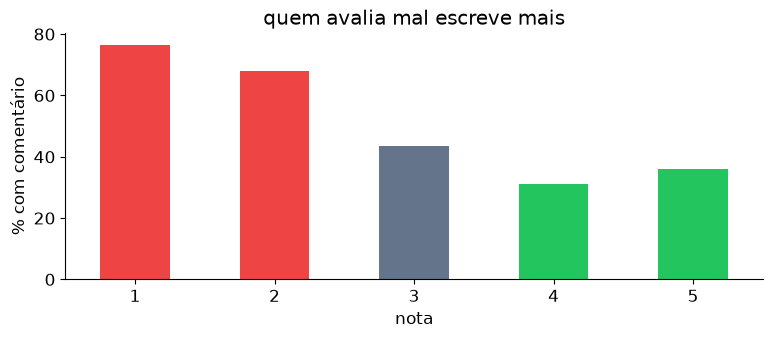

nota
1    76.5
2    68.1
3    43.5
4    31.2
5    35.9
Name: mensagem, dtype: float64

In [5]:
# por nota: a % das avaliações que têm comentário (mensagem não nula)
taxa = avaliacoes.groupby("nota")["mensagem"].apply(lambda s: 100 * s.notna().mean())

# barras por nota: 1 e 2 em vermelho, 3 em cinza, 4 e 5 em verde
ax = taxa.plot.bar(color=[RED, RED, GRAY, GREEN, GREEN], rot=0)

ax.set_ylabel("% com comentário")
ax.set_title("quem avalia mal escreve mais")
plt.show()
taxa.round(1)


O texto como está no arquivo: `repr` mostra os espaços sobrando e as quebras de linha (`\r\n`)
que a tela esconde.

In [6]:
EXEMPLOS = [69, 29336, 279, 23817]  # posições de quatro avaliações em mensagens
for i in EXEMPLOS:
    # o texto cru, com repr
    print(repr(mensagens["mensagem"][i]))


'fiz minha compra faz 30 dias e não recebi ainda meu produto.\r\nPrecisa melhorar nas entregas'
'Embora tenha pago R$88,46 (2 relógios e frete) só recebi um. Espero q vcs averiguem e me informem. Continuo aguardando'
'Produto perfeito, entrega rápida. Estou satisfeitíssima. 👏🏽'
'MEU PRODUTO VEIO ERRADO.\r\n\r\nPAGUEI CASAL KING R$ 99,00 - NÂO CASAL PADRAO. QUERO TROCA URGENTE.'


## 2. Corpus, token e tipo

**Corpus** é o conjunto de textos analisado: a coluna `mensagem`. **Token** é cada pedaço em que
o texto é cortado para ser contado. **Tipo** é um token único: as repetições contam uma vez só;
os tipos do corpus formam o **vocabulário**. Começamos com um regex simples: sequências de letras
ou dígitos.

In [7]:
frase = "Até agora não recebi nada, a colcha estava prevista para anteontem(18/12) e até agora nada"
# os tokens: cada sequência de letras ou dígitos (\w+)
tokens = re.findall(r"\w+", frase)
# os tipos: os tokens únicos, em minúsculas, com a contagem de cada um
tipos = Counter(t.lower() for t in tokens)

print(len(tokens), "tokens:", tokens)
print(len(tipos), "tipos (tokens únicos):", tipos.most_common(4))


17 tokens: ['Até', 'agora', 'não', 'recebi', 'nada', 'a', 'colcha', 'estava', 'prevista', 'para', 'anteontem', '18', '12', 'e', 'até', 'agora', 'nada']
14 tipos (tokens únicos): [('até', 2), ('agora', 2), ('nada', 2), ('não', 1)]


## 3. Da sentença ao byte

**Unicode** é o padrão que dá um número a cada caractere de todas as escritas, emojis incluídos:
o **ponto de código**, escrito U+ e o número em hexadecimal (é = U+00E9). O UTF-8 grava cada
número em 1 a 4 bytes. **Grafema** é o caractere que o leitor vê na tela; pode ser feito de mais
de um ponto de código: 👍🏻 é o polegar (U+1F44D) mais o tom de pele (U+1F3FB).

In [8]:
import regex  # o módulo regex entende \X (grafema)

frase = "Produto bem acabado 👍🏻"
# os grafemas: o que o leitor vê (\X do módulo regex)
grafemas = regex.findall(r"\X", frase)
print(len(grafemas), "grafemas:", grafemas)

# os pontos de código: ord dá o número; U+XXXX é esse número em hexadecimal
pontos = [f"U+{ord(ch):04X}" for ch in frase]
print(len(pontos), "pontos de código:", pontos)

# os bytes em UTF-8
print(len(frase.encode("utf-8")), "bytes")


21 grafemas: ['P', 'r', 'o', 'd', 'u', 't', 'o', ' ', 'b', 'e', 'm', ' ', 'a', 'c', 'a', 'b', 'a', 'd', 'o', ' ', '👍🏻']
22 pontos de código: ['U+0050', 'U+0072', 'U+006F', 'U+0064', 'U+0075', 'U+0074', 'U+006F', 'U+0020', 'U+0062', 'U+0065', 'U+006D', 'U+0020', 'U+0061', 'U+0063', 'U+0061', 'U+0062', 'U+0061', 'U+0064', 'U+006F', 'U+0020', 'U+1F44D', 'U+1F3FB']
28 bytes


## 4. Split por espaço

A régua mais simples não usa regex: `texto.split(" ")` corta em cada caractere de espaço.

In [9]:
reclamacao = mensagens["mensagem"][69]
# corte em cada caractere de espaço
print(reclamacao.split(" "))


['fiz', 'minha', 'compra', 'faz', '30', 'dias', 'e', 'não', 'recebi', 'ainda', 'meu', 'produto.\r\nPrecisa', 'melhorar', 'nas', 'entregas']


A quebra de linha não é espaço: `"produto.\r\nPrecisa"` vira um token só. Sem argumento,
`split()` corta em qualquer espaço em branco, quebras de linha incluídas:

In [10]:
# corte em qualquer espaço em branco (espaço, \r, \n)
print(reclamacao.split())


['fiz', 'minha', 'compra', 'faz', '30', 'dias', 'e', 'não', 'recebi', 'ainda', 'meu', 'produto.', 'Precisa', 'melhorar', 'nas', 'entregas']


## 5. Regex: o que é

Um regex é um padrão que descreve um trecho de texto. `\d{1,2}/\d{1,2}` lê-se "um ou dois
dígitos, uma barra, um ou dois dígitos": acha datas como 18/12. Quem cita uma data?

In [11]:
# marque as mensagens que contêm uma data (o padrão acima)
tem_data = mensagens["mensagem"].str.contains(r"\d{1,2}/\d{1,2}")
print(f"{br(tem_data.sum())} avaliações citam uma data")

# as 10 primeiras
for texto in mensagens.loc[tem_data, "mensagem"].head(10):
    print("·", texto)


616 avaliações citam uma data
· Foi marcado o dia 14/02 para entrega do pedido e no rastreamento marcava que o produto já havia sido entregue na data mas na realidade não foi entregue. O produto só foi entregue no dia 28/02.
· A targaryen não é de confiança não entregou a minha compra e colocou no rastreamento do pedido que foi entregue no dia 14/12/17 empresa falsa quero receber meus produtos que foram pagos com boleto bancari
· Até agora não recebi nada, a colcha estava prevista para anteontem(18/12) e até agora nada
· Previsão de entrega até 18/10, recebi em 05/10, excelente.
· O produto foi encaminhado para cidade de destino no dia 31/03 e até o momento não recebi.
· Obrigada pela qualidade do produto, e pela entrega tbm que era previsto para 10/08 e chegou dia 22/07. Adorei. Parabéns.
· ENTREGA MUITO DEMORADA, COMPREI EM 26/03/2018 E ATÉ AGORA NÃO RECEBI OS PRODUTOS
· ainda nao recebi e a ultima informacao sobre p produto e do dia 08/12/2017.
· Comprei duas bonecas baby kiss Sid n

Data aparece em reclamação de prazo: "prevista para 18/12", "comprei em 26/03 e até agora não recebi".

## 6. Regex como régua de tokens

Quatro padrões, cada um corrigindo um defeito do anterior:

| padrão | lê-se | defeito |
|---|---|---|
| `\S+` | tudo que não é espaço | a pontuação gruda: "prazo." ≠ "prazo" |
| `\w+` | letras, dígitos e `_` | solta a pontuação, mas parte "R$88,46" em "88" e "46" e perde o emoji |
| `[^\W\d_]+` | só letras (acentuadas também) | perde os números |
| composto | URL, ou dinheiro, ou número, ou palavra, ou emoji | a ordem das alternativas decide: a primeira que casa vence |

In [12]:
COMPOSTO = (r"https?://\S+|www\.\S+"                      # URL
            r"|R\$\s?\d+(?:[.,]\d+)*"                     # dinheiro
            r"|\d+(?:[.,]\d+)*%?"                         # número
            r"|[^\W\d_]+(?:[-'’][^\W\d_]+)*"              # palavra, com hífen ou apóstrofo
            r"|[\U0001F300-\U0001FAFF☀-➿][\U0001F3FB-\U0001F3FF]?")  # emoji com tom de pele


def tokenizar(texto):
    return re.findall(COMPOSTO, texto)


PADROES = {"\\S+": r"\S+", "\\w+": r"\w+", "só letras": r"[^\W\d_]+", "composto": COMPOSTO}
exemplos = ["pago R$88,46 (2 relógios e frete)", "entrega rápida. Estou satisfeitíssima. 👏🏽"]
for nome, padrao in PADROES.items():
    # os tokens que o padrão tira de cada exemplo
    print(f"{nome:<10}", [re.findall(padrao, t) for t in exemplos])


\S+        [['pago', 'R$88,46', '(2', 'relógios', 'e', 'frete)'], ['entrega', 'rápida.', 'Estou', 'satisfeitíssima.', '👏🏽']]
\w+        [['pago', 'R', '88', '46', '2', 'relógios', 'e', 'frete'], ['entrega', 'rápida', 'Estou', 'satisfeitíssima']]
só letras  [['pago', 'R', 'relógios', 'e', 'frete'], ['entrega', 'rápida', 'Estou', 'satisfeitíssima']]
composto   [['pago', 'R$88,46', '2', 'relógios', 'e', 'frete'], ['entrega', 'rápida', 'Estou', 'satisfeitíssima', '👏🏽']]


In [13]:
for nome, padrao in PADROES.items():
    # os tipos (tokens únicos) que o padrão gera no corpus inteiro
    tipos = {t for m in mensagens["mensagem"] for t in re.findall(padrao, m)}
    print(f"{nome:<10} {br(len(tipos))} tipos")


\S+        35.098 tipos


\w+        20.219 tipos


só letras  19.547 tipos

composto   20.291 tipos


## 7. Três tokenizadores pré-treinados

NLTK e spaCy aplicam regras do português escritas por outras pessoas; o tokenizador do GPT
corta em pedaços aprendidos num corpus enorme. Nenhum é treinado aqui.

In [14]:
import spacy
import tiktoken
from nltk.tokenize import word_tokenize

nlp = spacy.load("pt_core_news_sm", exclude=["tok2vec", "morphologizer", "parser", "lemmatizer",
                                              "attribute_ruler", "ner", "senter"])
gpt = tiktoken.get_encoding("o200k_base")
reguas = {
    "NLTK": lambda t: word_tokenize(t, language="portuguese"),
    "spaCy": lambda t: [tok.text for tok in nlp.tokenizer(t) if not tok.is_space],
    "GPT": lambda t: [gpt.decode([i]) for i in gpt.encode(t)],
}
exemplo = "Embora tenha pago R$88,46 (2 relógios e frete) só recebi um."
for nome, cortar in reguas.items():
    # corte o exemplo e mostre os pedaços
    pedacos = cortar(exemplo)
    print(f"{nome:<6} {len(pedacos)} tokens:", pedacos)


NLTK   16 tokens: ['Embora', 'tenha', 'pago', 'R', '$', '88,46', '(', '2', 'relógios', 'e', 'frete', ')', 'só', 'recebi', 'um', '.']
spaCy  15 tokens: ['Embora', 'tenha', 'pago', 'R$', '88,46', '(', '2', 'relógios', 'e', 'frete', ')', 'só', 'recebi', 'um', '.']
GPT    21 tokens: ['Embora', ' tenha', ' pago', ' R', '$', '88', ',', '46', ' (', '2', ' relóg', 'ios', ' e', ' fre', 'te', ')', ' só', ' rece', 'bi', ' um', '.']


O GPT parte palavras raras em pedaços conhecidos ("relóg", "ios"). Por isso a conta de um
modelo de linguagem é em tokens: o mesmo texto custa mais tokens em português que em inglês.

In [15]:
pares = [("Não recebi o produto e ninguém responde.", "I did not receive the product and nobody answers."),
         ("Veio com defeito e quero meu dinheiro de volta.", "It came defective and I want my money back.")]
for pt, en in pares:
    # quantos tokens do GPT cada versão gasta
    print(len(gpt.encode(pt)), "tokens em português ·", len(gpt.encode(en)), "em inglês")


9 tokens em português · 10 em inglês
12 tokens em português · 10 em inglês


## 8. Estatísticas do corpus

Daqui em diante, a régua é o padrão composto, em minúsculas.

In [16]:
# cada mensagem tokenizada pelo padrão composto, em minúsculas
docs = [[t.lower() for t in tokenizar(m)] for m in mensagens["mensagem"]]
# a contagem de cada tipo no corpus inteiro
contagem = Counter(t for d in docs for t in d)
# quantos tokens tem cada mensagem
n_tokens = pd.Series([len(d) for d in docs])

print(f"mediana {n_tokens.median():.0f} tokens; 90% têm até {n_tokens.quantile(0.9):.0f}")
print(f"vocabulário: {br(len(contagem))} tipos (tokens únicos)")
contagem.most_common(10)


mediana 9 tokens; 90% têm até 28
vocabulário: 15.828 tipos (tokens únicos)


[('o', 18826),
 ('produto', 18429),
 ('e', 15813),
 ('a', 12278),
 ('de', 11326),
 ('do', 11157),
 ('não', 10787),
 ('prazo', 8475),
 ('que', 8324),
 ('muito', 7925)]

## 9. Stopwords

A lista do NLTK tira palavras funcionais ("o", "de", "e"), mas também "não". Uma lista
customizada devolve as palavras que têm sentido nas reclamações.

In [17]:
from nltk.corpus import stopwords

nltk_stop = set(stopwords.words("portuguese"))
COM_SENTIDO = {"não", "nem", "sem", "muito", "mais", "já", "até", "só"}  # negação, falta, intensidade, tempo
# a lista customizada: a do NLTK sem as palavras com sentido
stop = nltk_stop - COM_SENTIDO

frase = "ainda não recebi o produto".split()
# a frase sem as stopwords de cada lista
print("NLTK:       ", [t for t in frase if t not in nltk_stop])
print("customizada:", [t for t in frase if t not in stop])
# as palavras mais frequentes do corpus, sem as stopwords customizadas
print("sem stopwords:", [(t, n) for t, n in contagem.most_common(40) if t not in stop][:8])


NLTK:        ['ainda', 'recebi', 'produto']
customizada: ['ainda', 'não', 'recebi', 'produto']
sem stopwords: [('produto', 18429), ('não', 10787), ('prazo', 8475), ('muito', 7925), ('entrega', 6531), ('antes', 5626), ('chegou', 5555), ('recebi', 5275)]


## 10. Zipf

Ordenadas da mais usada para a menos usada, as palavras perdem frequência depressa e sempre
do mesmo jeito, com ou sem stopwords.

In [18]:
# o ranking: pares (palavra, vezes), da mais usada para a menos usada
ranking = contagem.most_common()
# o mesmo ranking sem as stopwords customizadas
sem_stop = [(t, n) for t, n in ranking if t not in stop]

for nome, lista in [("com stopwords", ranking), ("sem stopwords", sem_stop)]:
    print(nome)
    # a frequência da 1ª colocada, para comparar
    primeira = lista[0][1]
    for posto in [1, 10, 100, 1000]:
        # a palavra no posto e quantas vezes ela aparece (a lista começa em 0)
        palavra, n = lista[posto - 1]
        # quantas vezes menos que a 1ª colocada
        print(f"  posto {posto:>5}: {palavra:<12} {br(n):>7} vezes · {primeira / n:.1f}× menos que a 1ª")

# só as contagens, na ordem do ranking
freqs = np.array([n for _, n in ranking])
# quantos tipos aparecem uma vez só
print(f"{br((freqs == 1).sum())} tipos ({br(100 * (freqs == 1).mean(), 0)}%) aparecem uma vez só")


com stopwords
  posto     1: o             18.826 vezes · 1.0× menos que a 1ª
  posto    10: muito          7.925 vezes · 2.4× menos que a 1ª
  posto   100: satisfeita       699 vezes · 26.9× menos que a 1ª
  posto  1000: aberta            38 vezes · 495.4× menos que a 1ª
sem stopwords
  posto     1: produto       18.429 vezes · 1.0× menos que a 1ª
  posto    10: recomendo      4.333 vezes · 4.3× menos que a 1ª
  posto   100: bonito           467 vezes · 39.5× menos que a 1ª
  posto  1000: avariado          33 vezes · 558.5× menos que a 1ª
8.238 tipos (52%) aparecem uma vez só


In [19]:
# onde começa a cauda: os tipos com 5 ocorrências ou mais vêm antes desse posto
corte = (freqs >= 5).sum()
# cabeça, meio e cauda do ranking
zonas = {"cabeça (100 mais)": freqs[:100], "meio (≥ 5 vezes)": freqs[100:corte], "cauda (< 5 vezes)": freqs[corte:]}
# para cada zona: a parte do texto (ocorrências) e a parte do vocabulário (tipos)
pd.DataFrame({"% do texto": {z: 100 * f.sum() / freqs.sum() for z, f in zonas.items()},
              "% do vocabulário": {z: 100 * len(f) / len(freqs) for z, f in zonas.items()}}).round(1)


,% do texto,% do vocabulário
cabeça (100 mais),61.9,0.6
meio (≥ 5 vezes),34.3,23.5
cauda (< 5 vezes),3.8,75.9


A cabeça (stopwords e o assunto geral) faz 62% do texto; a cauda (erros de digitação e
variantes) é três quartos do vocabulário e menos de 4% do texto. As reclamações estão no meio.

## 11. A primeira resposta: as palavras das reclamações

**A pergunta: do que reclamam os clientes?** A primeira resposta são os pares de palavras
seguidas (*bigramas*) muito mais comuns nas avaliações ruins do que nas boas. A medida é a % das
avaliações de cada grupo que contêm o bigrama.

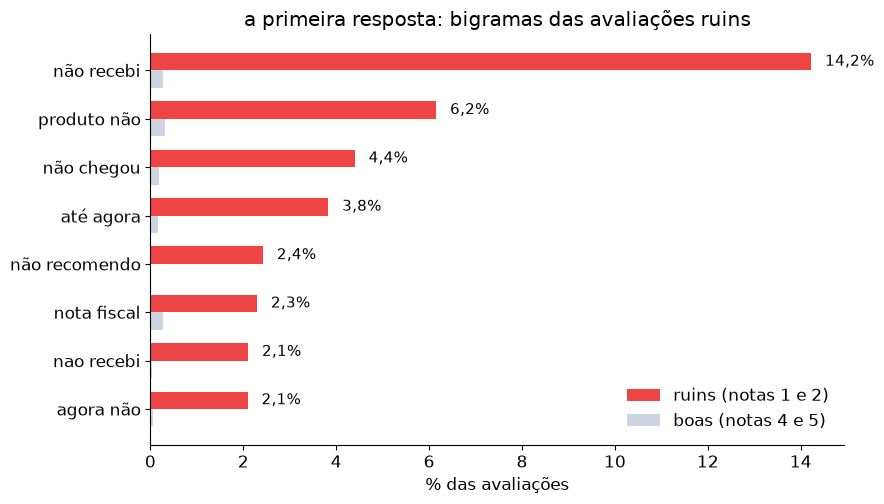

,ruins,boas
bigramas,,
não recebi,14.2,0.3
produto não,6.2,0.3
não chegou,4.4,0.2
até agora,3.8,0.2
não recomendo,2.4,0.0
nota fiscal,2.3,0.3
nao recebi,2.1,0.0
agora não,2.1,0.1


In [20]:
# os bigramas de cada avaliação, sem repetição
mensagens["bigramas"] = [list({f"{a} {b}" for a, b in zip(d, d[1:])}) for d in docs]
# uma linha por avaliação e bigrama
pares = mensagens[["grupo", "bigramas"]].explode("bigramas", ignore_index=True)
# em quantas avaliações de cada grupo cada bigrama aparece
contas = pd.crosstab(pares["bigramas"], pares["grupo"])

# o bigrama tem stopword? (alguma das duas palavras na lista)
com_stop = contas.index.map(lambda b: any(w in stop for w in b.split()))
# fica com os frequentes (40 avaliações ou mais) e sem stopword
contas = contas[(contas["ruim"] + contas["boa"] >= 40) & ~com_stop]

# a % das avaliações ruins e das boas que têm o bigrama
pista = pd.DataFrame({"ruins": 100 * contas["ruim"] / (mensagens["grupo"] == "ruim").sum(),
                      "boas": 100 * contas["boa"] / (mensagens["grupo"] == "boa").sum()})
# os 8 mais citados nas ruins, entre os que são 8 vezes (ou mais) mais comuns nas ruins
pista = pista[pista["ruins"] >= 8 * pista["boas"]].sort_values("ruins", ascending=False).head(8)

grafico_ruins_boas(pista.index, pista["ruins"], pista["boas"], "a primeira resposta: bigramas das avaliações ruins")
pista.round(1)


Como ler: "não recebi" está em 14% das avaliações ruins e em 0,3% das boas, cerca de 50 vezes mais.

**Resposta:** a entrega domina. "não recebi", "não chegou", "até agora" e "agora não" dizem que o
produto não chegou ou atrasou.

## 12. O que essa contagem ainda não sabe

"não recebi" e "nao recebi" contam separado, e a mesma avaliação pode entrar mais de uma vez.
É o assunto do próximo laboratório: higiene de corpus.

In [21]:
# em quantas mensagens aparece cada grafia do bigrama
print("não recebi:", (pares["bigramas"] == "não recebi").sum(), "mensagens")
print("nao recebi:", (pares["bigramas"] == "nao recebi").sum(), "mensagens")
# quantos review_id aparecem repetidos
print("review_id repetidos:", mensagens["review_id"].duplicated().sum())


não recebi: 1769 mensagens
nao recebi: 266 mensagens
review_id repetidos: 309
